# Myocardial Diffusion Model

## Setup

This project requires Python 3.7 or above:

In [18]:
import sys
assert sys.version_info >= (3, 7)

It also requires Scikit-Learn ≥ 1.0.1:

In [19]:
from packaging import version
import sklearn
assert version.parse(sklearn.__version__) >= version.parse("1.0.1")

**Warning**: the latest TensorFlow versions are based on Keras 3. Unfortunately it's much harder for this, in particular adding custom losses using the functional API is not implemented yet. So for this Model I've had to revert to Keras 2. To do that, I set the `TF_USE_LEGACY_KERAS` environment variable to `"1"` and import the `tf_keras` package. This ensures that `tf.keras` points to `tf_keras`, which is Keras 2.*.

In [20]:
import importlib
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"
import tf_keras

And TensorFlow ≥ 2.8:

In [21]:
import tensorflow as tf
assert version.parse(tf.__version__) >= version.parse("2.8.0")

Let's define the default font sizes to make the figures prettier:

In [22]:
import matplotlib.pyplot as plt

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

And let's create the `images/generative` folder (if it doesn't already exist), and define the `save_fig()` function which is used through this notebook to save the figures in high-res for the report:

In [23]:
from pathlib import Path

IMAGES_PATH = Path() / "images" / "generative"
IMAGES_PATH.mkdir(parents=True, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=256):
    path = IMAGES_PATH / f"{fig_id}.{fig_extension}"
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

This chapter can be very slow without a GPU, so let's make sure there's one, or else issue a warning:

In [24]:
import sys, os
print("Python Executable:", sys.executable)
print("Platform:", sys.platform)
print("LD_LIBRARY_PATH:", os.environ.get("LD_LIBRARY_PATH", "NOT SET"))

Python Executable: /home/molham/miniconda3/envs/myocardial-gdm/bin/python
Platform: linux
LD_LIBRARY_PATH: /usr/lib/wsl/lib:/home/molham/miniconda3/envs/myocardial-gdm/lib/python3.10/site-packages/tensorflow:


In [25]:
if not tf.config.list_physical_devices('GPU'):
    print("No GPU was detected. Neural nets can be very slow without a GPU.")
    if "google.colab" in sys.modules:
        print("Go to Runtime > Change runtime and select a GPU hardware "
              "accelerator.")
    if "kaggle_secrets" in sys.modules:
        print("Go to Settings > Accelerator and select GPU.")
else:
    print("GPU detected. You are good to go!")

GPU detected. You are good to go!


## MyoPS data and plotting setup

Use only the still 3D volumes in `MyoPS_train` and `MyoPS_val`; pair LGE with the available C0 (static bSSFP) or T2 target within each case. Cases missing a target are excluded from that modality's supervised loss but can still be used for inference.


In [26]:
import os
import sys
import numpy as np
from pathlib import Path

module_dir = next(
    (path.resolve() for path in
     (Path.cwd(), Path.cwd() / "myocardial-gdm", Path.cwd().parent / "myocardial-gdm")
     if (path / "myocardial_data.py").is_file()),
    None,
)
if module_dir is None:
    raise FileNotFoundError("Could not locate myocardial_data.py")
sys.path.insert(0, str(module_dir))
import myocardial_data
importlib.reload(myocardial_data)

from myocardial_data import (
    TARGET_MODALITIES,
    build_conditional_diffusion_model,
    find_paired_cases,
    generate_conditioned,
    load_aligned_pair,
    load_lge_volume,
    make_paired_dataset,
    paired_case_counts,
    synthesize_volume,
)

data_root_candidates = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]
if os.environ.get("MYO_DATA_ROOT"):
    data_root_candidates.insert(0, Path(os.environ["MYO_DATA_ROOT"]).expanduser())
DATA_ROOT = next(
    (path.resolve() for path in data_root_candidates
     if (path / "Myo_train" / "MyoPS_train").is_dir()),
    None,
)
if DATA_ROOT is None:
    raise FileNotFoundError(
        "Set MYO_DATA_ROOT to the directory containing Myo_train and Myo_val"
    )

TRAIN_PAIRS = find_paired_cases(DATA_ROOT / "Myo_train" / "MyoPS_train")
VALID_PAIRS = find_paired_cases(DATA_ROOT / "Myo_val" / "MyoPS_val")
print("Training paired cases:", dict(paired_case_counts(TRAIN_PAIRS)))
print("Validation paired cases:", dict(paired_case_counts(VALID_PAIRS)))

def plot_multiple_images(images, n_cols=8):
    images = np.asarray(images)
    if images.ndim == 4 and images.shape[-1] == 1:
        images = images[..., 0]
    n_images = len(images)
    n_rows = (n_images - 1) // n_cols + 1
    plt.figure(figsize=(n_cols * 1.5, n_rows * 1.5))
    for index, image in enumerate(images):
        plt.subplot(n_rows, n_cols, index + 1)
        plt.imshow(image, cmap="gray", vmin=-1, vmax=1)
        plt.axis("off")


Training paired cases: {'C0': 104, 'T2': 80}
Validation paired cases: {'C0': 15, 'T2': 15}


# Diffusion Models

For each paired training slice, the forward diffusion process adds Gaussian noise to the target (C0 or T2) image. The denoiser receives that noisy target, its aligned LGE source slice, the diffusion time, and the requested target modality, then predicts the added noise. This makes generation conditional on both LGE anatomy and whether C0/bSSFP or T2 is requested.

The [DDPM paper](https://arxiv.org/abs/2006.11239) increased $\beta_t$ from $\beta_1$ = 0.0001 to $\beta_T = $0.02 ($T$ is the max step), but the [Improved DDPM paper](https://arxiv.org/pdf/2102.09672.pdf) suggested using the following $\cos^2(\ldots)$ schedule instead, which gradually decreases $\bar{\alpha_t} = \prod_{i=0}^{t} \alpha_i$ from 1 to 0, where $\alpha_t = 1 - \beta_t$:

In [27]:
def variance_schedule(T, s=0.008, max_beta=0.999):
    t = np.arange(T + 1)
    f = np.cos((t / T + s) / (1 + s) * np.pi / 2) ** 2
    alpha = np.clip(f[1:] / f[:-1], 1 - max_beta, 1)
    alpha = np.append(1, alpha).astype(np.float32)  # add α₀ = 1
    beta = 1 - alpha
    alpha_cumprod = np.cumprod(alpha)
    return alpha, alpha_cumprod, beta  # αₜ , α̅ₜ , βₜ for t = 0 to T

np.random.seed(42)  # extra code – for reproducibility
T = 1000
alpha, alpha_cumprod, beta = variance_schedule(T)

Use $T = 1,000$ for training. The variable `alpha` contains $\alpha_0, ..., \alpha_T$, and `alpha_cumprod` contains $\bar{\alpha_0}, ..., \bar{\alpha_T}$. Synthesis uses 100 deterministic DDIM steps by default rather than evaluating all 1,000 reverse steps.

Let's plot `alpha_cumprod`:

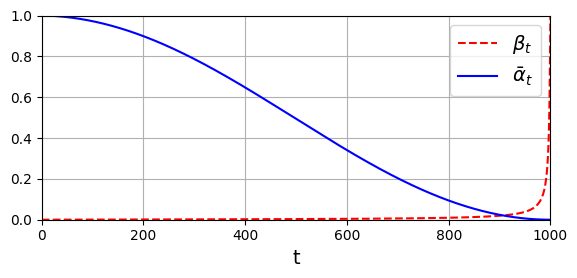

In [28]:
# extra code – this cell generates and saves Figure 17–21
plt.figure(figsize=(6, 3))
plt.plot(beta, "r--", label=r"$\beta_t$")
plt.plot(alpha_cumprod, "b", label=r"$\bar{\alpha}_t$")
plt.axis([0, T, 0, 1])
plt.grid(True)
plt.xlabel(r"t")
plt.legend()
save_fig("variance_schedule_plot")
plt.show()

The paired input pipeline streams slices from disk and adds noise to each target slice at an independently sampled time between 1 and $T$. It returns the conditional inputs and the noise targets:

* The inputs contain the noisy target, aligned LGE source, time index, and target-modality ID. Noise is added in one step using equation (4) from the DDPM paper.
* The target is the noise that was used to produce the noisy images.

In [29]:
# The paired MyoPS dataset builder adds diffusion noise after resizing paired slices.

Now let's prepare a `tf.data.Dataset` for training, and one for validation.

In [30]:
IMAGE_SIZE = 128
BATCH_SIZE = 16
tf.random.set_seed(43)
train_set = make_paired_dataset(
    TRAIN_PAIRS, alpha_cumprod, T, image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE, shuffle=True,
)
valid_set = make_paired_dataset(
    VALID_PAIRS, alpha_cumprod, T, image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
)

As a quick sanity check, let's take a look at a few training samples, along with the corresponding noise to predict, and the original images (which we get by subtracting the appropriately scaled noise from the appropriately scaled noisy image):

LGE conditions


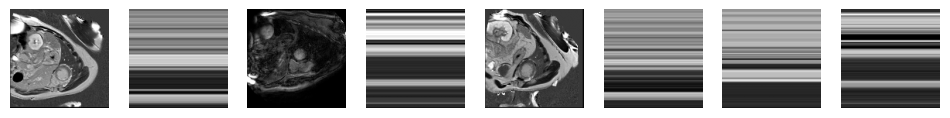

Target modalities: [b'C0 / bSSFP', b'C0 / bSSFP', b'C0 / bSSFP', b'T2', b'C0 / bSSFP', b'T2', b'T2', b'C0 / bSSFP']
Original target images reconstructed from the forward process


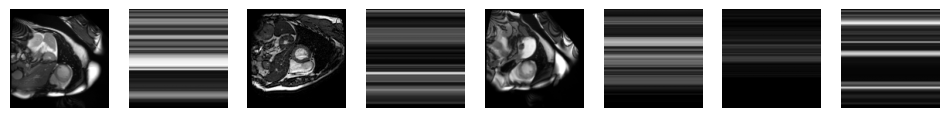

Time steps: [405 312 441 991 443 657 308 151]
Noisy images


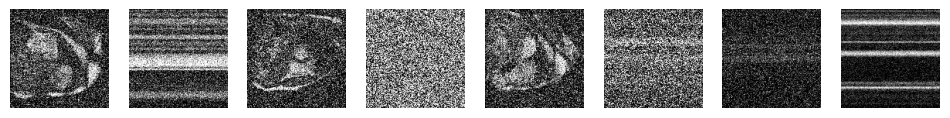

Noise to predict


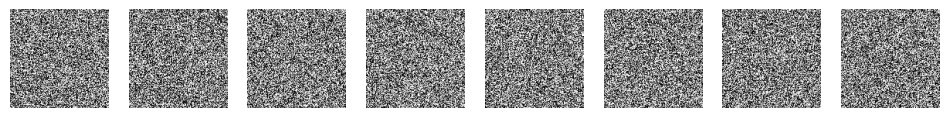

In [31]:
# extra code – just a quick sanity check

def subtract_noise(X_noisy, time, noise):
    X_shape = tf.shape(X_noisy)
    alpha_cm = tf.gather(alpha_cumprod, time)
    alpha_cm = tf.reshape(alpha_cm, [X_shape[0]] + [1] * (len(X_shape) - 1))
    return (X_noisy - (1 - alpha_cm) ** 0.5 * noise) / alpha_cm ** 0.5

X_dict, Y_noise = list(train_set.take(1))[0]  # get the first batch
X_original = subtract_noise(X_dict["X_noisy"], X_dict["time"], Y_noise)

print("LGE conditions")
plot_multiple_images(X_dict["X_condition"][:8].numpy())
plt.show()
modality_names = tf.gather(tf.constant(["C0 / bSSFP", "T2"]), X_dict["modality"][:8])
print("Target modalities:", modality_names.numpy().tolist())
print("Original target images reconstructed from the forward process")
plot_multiple_images(X_original[:8].numpy())
plt.show()
print("Time steps:", X_dict["time"].numpy()[:8])
print("Noisy images")
plot_multiple_images(X_dict["X_noisy"][:8].numpy())
plt.show()
print("Noise to predict")
plot_multiple_images(Y_noise[:8].numpy())
plt.show()

The U-Net jointly processes the noisy target and the LGE condition. Sinusoidal timestep encodings and a learned C0/T2 modality embedding are injected into its down- and up-sampling blocks.

In [32]:
embed_size = 64

The model predicts noise in a 128 × 128 target slice. It uses the LGE slice as a spatial condition, and a two-entry modality embedding distinguishes C0/bSSFP synthesis from T2 synthesis. The three down/up-sampling stages use skip connections to retain spatial detail.

In [33]:
def build_diffusion_model():
    return build_conditional_diffusion_model(
        timesteps=T, image_size=IMAGE_SIZE, embedding_size=embed_size
    )

Let's train the model!

In [34]:
tf.random.set_seed(42)
model = build_diffusion_model()
model.compile(loss=tf.keras.losses.Huber(), optimizer=tf.keras.optimizers.Nadam())

checkpoint_cb = tf.keras.callbacks.ModelCheckpoint("myocardial_conditional_diffusion.keras",
                                                   save_best_only=True)

history = model.fit(train_set, validation_data=valid_set, epochs=100,
                    callbacks=[checkpoint_cb])

Epoch 1/100


E0000 00:00:1792082183.166327    1170 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape ingradient_tape/huber_loss/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


     87/Unknown - 17s 64ms/step - loss: 0.3273

I0000 00:00:1792082197.684683   41457 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 11578985593895166154
I0000 00:00:1792082197.684715   41457 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 2241169014251298574


88/88 [==============================] - 18s 76ms/step - loss: 0.3272 - val_loss: 0.4204
Epoch 2/100
45/88 [==============>...............] - ETA: 3s - loss: 0.1191

KeyboardInterrupt: 

### Training results

Compare training and validation loss across epochs to check whether the denoising model is learning and generalizing.


In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(history.history["loss"], label="Training loss")
ax.plot(history.history["val_loss"], label="Validation loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Huber loss")
ax.set_title("Diffusion model training history")
ax.grid(True)
ax.legend()
save_fig("ddpm_training_history_plot")
plt.show()


Generate a target slice from an LGE slice while conditioning on the requested target modality. Accelerated deterministic DDIM sampling uses a subset of diffusion steps. `synthesize_volume()` applies this slice-wise to an LGE NIfTI and optionally saves a 3D prediction on its voxel grid.

In [ ]:
tf.random.set_seed(42)
example = next(record for record in VALID_PAIRS if record.target_modality == "T2")
lge_image, lge_volume, target_volume = load_aligned_pair(example)
slice_index = lge_volume.shape[2] // 2
lge_slice = tf.image.resize(
    lge_volume[:, :, slice_index, np.newaxis], (IMAGE_SIZE, IMAGE_SIZE)
)
prediction = generate_conditioned(
    model, lge_slice[np.newaxis, ...], example.target_modality,
    alpha_cumprod, T, sampling_steps=100,
)[0, ..., 0]
prediction = tf.image.resize(
    prediction[..., np.newaxis], lge_volume.shape[:2]
)[..., 0].numpy()

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, image, title in zip(
    axes,
    (lge_volume[:, :, slice_index], target_volume[:, :, slice_index], prediction),
    ("LGE input", f"Reference {example.target_modality}", "Generated"),
):
    ax.imshow(image, cmap="gray", vmin=-1, vmax=1)
    ax.set_title(title)
    ax.axis("off")
plt.show()

In [ ]:
lge_only_root = DATA_ROOT / "Myo_train" / "MyoPS_train" / "CenterA"
lge_candidates = sorted(lge_only_root.rglob("*_LGE.nii.gz"))
if not lge_candidates:
    raise FileNotFoundError(f"No LGE volumes found under {lge_only_root}")
lge_path = lge_candidates[0]
case_id = lge_path.name.split("_")[0]
prediction_dir = Path("myo_predictions") / case_id
for target_modality in TARGET_MODALITIES:
    output_path = prediction_dir / f"{case_id}_{target_modality}_prediction.nii.gz"
    synthesize_volume(
        model, lge_path, target_modality, alpha_cumprod, T,
        image_size=IMAGE_SIZE, sampling_steps=100, output_path=output_path,
    )
    print(f"Saved normalized {target_modality} prediction to {output_path}")

The synthesized NIfTI volumes are stored in `myo_predictions/` on the canonical LGE voxel grid. Intensities are normalized to [-1, 1]; these are research image-synthesis outputs, not quantitative T2 maps or clinically validated predictions.